***PART_ONE***

In [16]:
import torch
import torchvision
from torchvision.transforms import v2

In [2]:
transform = v2.Compose(
    [
        v2.ToImage(),
        v2.ToDtype(torch.float32, scale=True),
        v2.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
    ]
)

batch_size = 64

trainset = torchvision.datasets.CIFAR10(
    root="./data", train=True, download=True, transform=transform
)
trainloader = torch.utils.data.DataLoader(
    trainset, batch_size=batch_size, shuffle=True, num_workers=2
)

testset = torchvision.datasets.CIFAR10(
    root="./data", train=False, download=True, transform=transform
)
testloader = torch.utils.data.DataLoader(
    testset, batch_size=batch_size, shuffle=False, num_workers=2
)

classes = (
    "plane",
    "car",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck",
)

100.0%


In [17]:
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)


class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.fc1 = nn.Linear(2048, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))
        x = torch.flatten(x, 1)  # flatten all dimensions except batch
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x


net = Net()

In [18]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=0.001)

In [20]:
import time

loss_part_one = []

if torch.cuda.is_available():
    torch.cuda.synchronize()
start_time = time.perf_counter()

for epoch in range(10):  # loop over the dataset multiple times
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data

        # zero the parameter gradients
        optimizer.zero_grad()

        # forward + backward + optimize
        outputs = net(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # print statistics
        running_loss += loss.item()
    error = running_loss / len(trainloader)
    loss_part_one.append(error)
    print(f"epoch: {epoch + 1} loss: {error:.3f}")

if torch.cuda.is_available():
    torch.cuda.synchronize()
part_one_time = time.perf_counter() - start_time
print(f" Training Time for part_one {part_one_time / 10:.2f} seconds")

print("Finished Training")

epoch: 1 loss: 0.986
epoch: 2 loss: 0.801
epoch: 3 loss: 0.688
epoch: 4 loss: 0.595
epoch: 5 loss: 0.513
epoch: 6 loss: 0.439
epoch: 7 loss: 0.377
epoch: 8 loss: 0.315
epoch: 9 loss: 0.266
epoch: 10 loss: 0.216
 Training Time for part_one 76.61 seconds
Finished Training


In [21]:
PATH = "./cifar_net_cnn.pt"
torch.save(net.state_dict(), PATH)

In [22]:
correct = 0
total = 0
# since we're not training, we don't need to calculate the gradients for our outputs
with torch.no_grad():
    for data in testloader:
        images, labels = data
        # calculate outputs by running images through the network
        outputs = net(images)
        # the class with the highest energy is what we choose as prediction
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f"Accuracy of the network on the 10000 test images: {100 * correct // total} %")

Accuracy of the network on the 10000 test images: 75 %


***PART_TWO***

In [30]:
torch.manual_seed(0)


class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.fc1 = nn.Linear(3072, 512)
        self.fc2 = nn.Linear(512, 256)
        self.fc3 = nn.Linear(256, 10)

    def forward(self, x):
        x = torch.flatten(x, 1)  # flatten all dimensions except batch
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x


mlp = MLP()

In [37]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(mlp.parameters(), lr=0.001)

In [38]:
loss_part_two = []

if torch.cuda.is_available():
    torch.cuda.synchronize()
start_time = time.perf_counter()

for epoch in range(10):  # loop over the dataset multiple times
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data

        # zero the parameter gradients
        optimizer.zero_grad()

        # forward + backward + optimize
        outputs = mlp(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # print statistics
        running_loss += loss.item()

    error = running_loss / len(trainloader)
    loss_part_two.append(error)
    print(f"epoch: {epoch + 1} loss: {error:.3f}")

if torch.cuda.is_available():
    torch.cuda.synchronize()
part_one_time = time.perf_counter() - start_time
print(f" Training Time for part_one {part_one_time / 10:.2f} seconds")


epoch: 1 loss: 1.638
epoch: 2 loss: 1.431
epoch: 3 loss: 1.321
epoch: 4 loss: 1.231
epoch: 5 loss: 1.144
epoch: 6 loss: 1.073
epoch: 7 loss: 1.003
epoch: 8 loss: 0.927
epoch: 9 loss: 0.854
epoch: 10 loss: 0.786
 Training Time for part_one 35.94 seconds


In [39]:
PATH = "./cifar_net_mlp.pt"
torch.save(mlp.state_dict(), PATH)

In [40]:
correct = 0
total = 0
# since we're not training, we don't need to calculate the gradients for our outputs
with torch.no_grad():
    for data in testloader:
        images, labels = data
        # calculate outputs by running images through the network
        outputs = mlp(images)
        # the class with the highest energy is what we choose as prediction
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f"Accuracy of the network on the 10000 test images: {100 * correct // total} %")

Accuracy of the network on the 10000 test images: 54 %


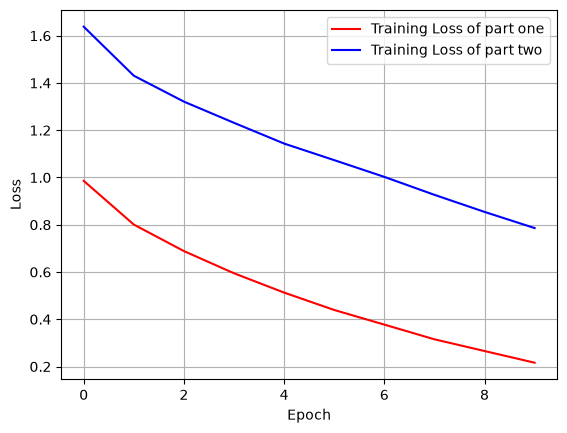

In [41]:
import matplotlib.pyplot as plt

plt.plot(loss_part_one, label="Training Loss of part one", c="r")
plt.plot(loss_part_two, label="Training Loss of part two", c="b")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.legend()
plt.show()

***What does the CNN assume about images that the MLP does not? Name both assumptions
and say what each one saves you? First Assumption: Spatial Locality: The CNN assumes that pixels close to each other are strongly correlated and form specific local features (such as edges and textures), unlike distant pixels. This assumption saves massive amounts of parameters by using small filters ($3\times3$) instead of connecting every pixel to all other pixels.***

***An MLPseesthe image as 3072 independent numbers. What happens to its learned weights if
every image is shifted two pixels to the right? What happens to the CNN’s?....For the MLP: The MLP views the image as 3072 completely independent numbers with no spatial awareness. Shifting the image two pixels to the right changes the inputs to all connected weights, forcing the MLP to treat it as a completely new input and relearn distinct weights for each pixel position to recognize the shifted pattern....For the CNN: Thanks to translation equivariance and parameter sharing, the filter extracts the exact same features (Feature Maps) merely shifted by two pixels in the output, allowing the learned weights to recognize objects regardless of their spatial location without needing to relearn them.***

## this code is not from Ai , but from the pytorch documentation itself !

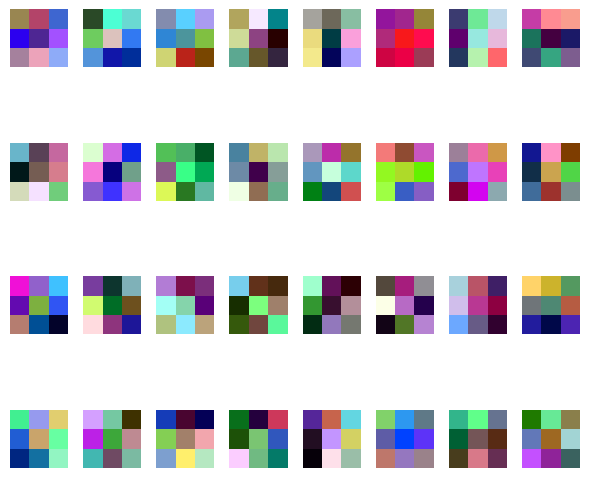

In [42]:
import numpy as np

filters = net.conv1.weight.data
filters = [l.permute(1, 2, 0) for l in filters]
filters = [(l - l.min()) / (l.max() - l.min()) for l in filters]

fig, axs = plt.subplots(4, 8, figsize=(6, 6))
axs = axs.flatten()
for i in range(32):
    axs[i].imshow(filters[i].cpu().numpy())
    axs[i].axis("off")  # hides ticks and borders for each small plot
plt.tight_layout()
plt.show()
